# AO simulation postprocessing

> !!! Batch saving not implemented !!!

In [ ]:
%matplotlib widget
import matplotlib.pyplot as plt
import h5py
import numpy as np
import pandas as pd
from matplotlib.patches import Circle
import os
import myfunctions
import h5py

# os.environ["CUDA_VISIBLE_DEVICES"] = "0,1,3" # https://discuss.pytorch.org/t/limit-process-to-single-gpu/55806/2
import TM26_unet as unet
import torch
from torch.utils.data import DataLoader, TensorDataset

metadata = myfunctions.read_metadata_file("dataInputs/metadata.txt")
exposureTime = metadata["exposureTime"]

## Inputs

In [2]:
GPU = True
MULTIGPU = True

DELETE_OLD_FILES = False

SMALL_SIZE = 18
MEDIUM_SIZE = 22
BIGGER_SIZE = 24
GPU = True
testDataDir = "output_prep/"
outputDir = "output_infer/"
inputDir = "output_ML/"

datasets_name = ["lightfield", "WFSxy", "WFSxy_DM", "WFSxy_DM_intensity", "WFSxy_intensity"]
dataset_name_readable = ["lightfield", "WFSxy", "WFSxy and DM commands", "WFSxy, SHWFS intensity map and DM commands", "WFSxy and SHWFS intensity map"]
input_channels = [1, 2, 3, 4, 3] # number of channels in the input data. For example, WFSxy has 2 channels (WFSx and WFSy) while lightfield has only 1 channel (lightfield image)
input_size = [(270, 270), (80, 80), (80, 80), (80, 80), (80, 80)]

batch_size = 64
dataset_number = 0 #len(datasets_name) # input number to select dataset

In [3]:
exposureTime = f"{exposureTime:,}".replace(",", " ")
subtitles = [f"Trained on {exposureTime} {dataset_name_readable[j]}" for j in range(len(dataset_name_readable))]
dataset_number = 0 #len(datasets_name)

for i in range(len(datasets_name)):
    os.makedirs(outputDir + datasets_name[i], exist_ok=True)

Epochs:  100


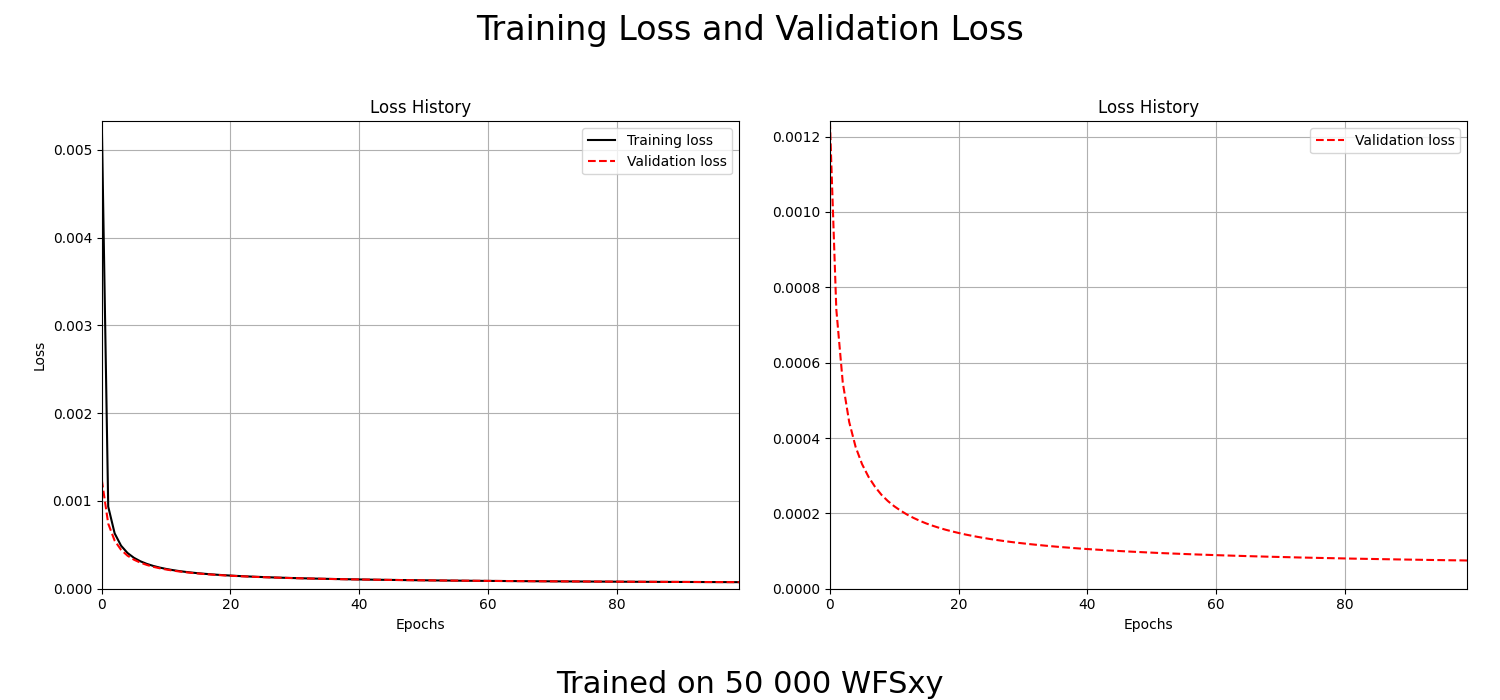

In [4]:
with h5py.File(inputDir+datasets_name[dataset_number]+"/history.h5", 'r') as history:
    key = list(history.keys())
    # print(key)
    loss = history['loss'][()]
    # print(history['loss'][()])
    val_loss = history['val_loss'][()]
    Epochs = len(loss)

print("Epochs: ", Epochs)

plt.close("all")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7))

ax1.plot(loss, "-k", label="Training loss")
ax1.plot(val_loss, "--r", label="Validation loss")
ax1.set_xlabel("Epochs")
ax1.set_ylabel("Loss")
ax1.set_title("Loss History")
ax1.legend()
ax1.set_xlim([0, Epochs-1])
ax1.set_ylim([0, max(max(loss), max(val_loss))])
ax1.grid()

ax2.plot(val_loss, "--r", label="Validation loss")
ax2.set_xlabel("Epochs")
# ax2.set_ylabel("Loss")
ax2.set_title("Loss History")
ax2.legend()
ax2.set_xlim([0, Epochs-1])
ax2.set_ylim([0, max(val_loss)])
ax2.grid()

plt.rc("font", size=MEDIUM_SIZE)
plt.rc("axes", titlesize=MEDIUM_SIZE)
plt.rc("axes", labelsize=SMALL_SIZE)
plt.rc("xtick", labelsize=SMALL_SIZE*.8)
plt.rc("ytick", labelsize=SMALL_SIZE*.8)
plt.rc("legend", fontsize=SMALL_SIZE)
plt.rc("figure", titlesize=MEDIUM_SIZE)
plt.suptitle("Training Loss and Validation Loss", fontsize=BIGGER_SIZE)
plt.figtext(0.5, 0.01, subtitles[1], ha="center", fontsize=MEDIUM_SIZE)
plt.tight_layout(rect=[0, 0.05, 1, 1])

plt.savefig(outputDir + datasets_name[1]+ "/loss.png")

## Load test data 

Except for when the lightfield is used, WFSx and WFSy are always used. Other cases are not handeled

In [8]:
x_max = np.genfromtxt(inputDir+datasets_name[0]+"/max_val.txt", delimiter=',', dtype=None, encoding='utf-8')[0][1]
y_max = np.genfromtxt(inputDir+datasets_name[0]+"/max_val.txt", delimiter=',', dtype=None, encoding='utf-8')[1][1]
print("x_max: ", x_max)
print("y_max: ", y_max)
print(inputDir+datasets_name[dataset_number]+"/max_val.txt")

print(f"Loading {dataset_name_readable[dataset_number]} data")
if datasets_name[dataset_number] == "lightfield":
    with h5py.File(testDataDir+"ao_lightfield_test_1.h5", 'r') as temp:
        key = list(temp.keys())
        x_test = temp[key[0]][()][:]
    with h5py.File(testDataDir+"ao_ipsf_test_1.h5", 'r') as temp:
        key = list(temp.keys())
        test_data = temp[key[0]][()][:]
        y_test = np.zeros((test_data.shape[0], *input_size[0]))
        for i in range(test_data.shape[0]):
            y_test[i] = myfunctions.pixel_adder(test_data[i], final_shape=[input_size[0][0], input_size[0][1]])

elif datasets_name[dataset_number] == "WFSxy":
    with h5py.File(testDataDir+"ao_WFSx"+"_test_1.h5", 'r') as temp:
        key = list(temp.keys())
        test_data = temp[key[0]][()][:]
        WFSx = np.zeros((test_data.shape[0], *input_size[1]))
        for i in range(test_data.shape[0]):
            WFSx[i] = myfunctions.pixel_adder(test_data[i], final_shape=[input_size[1][0], input_size[1][1]])
    with h5py.File(testDataDir+"ao_WFSy"+"_test_1.h5", 'r') as temp:
        key = list(temp.keys())
        test_data = temp[key[0]][()][:]
        WFSy = np.zeros((test_data.shape[0], *input_size[1]))
    for i in range(test_data.shape[0]):
            WFSy[i] = myfunctions.pixel_adder(test_data[i], final_shape=[input_size[1][0], input_size[1][1]])
    with h5py.File(testDataDir+"ao_ipsf_test_1.h5", 'r') as temp:
        key = list(temp.keys())
        y_test = temp[key[0]][()][:]
    
    x_test = np.stack((WFSx, WFSy), axis=1) # stack WFSx and WFSy along the channel dimension
    del WFSx, WFSy, test_data

elif datasets_name[dataset_number] == "WFSxy_DM":
    with h5py.File(testDataDir+"ao_WFSx"+"_test_1.h5", 'r') as temp:
        key = list(temp.keys())
        test_data = temp[key[0]][()][:]
        WFSx = np.zeros((test_data.shape[0], *input_size[1]))
        for i in range(test_data.shape[0]):
            WFSx[i] = myfunctions.pixel_adder(test_data[i], final_shape=[input_size[2][0], input_size[2][1]])
    with h5py.File(testDataDir+"ao_WFSy"+"_test_1.h5", 'r') as temp:
        key = list(temp.keys())
        test_data = temp[key[0]][()][:]
        WFSy = np.zeros((test_data.shape[0], *input_size[1]))
    for i in range(test_data.shape[0]):
            WFSy[i] = myfunctions.pixel_adder(test_data[i], final_shape=[input_size[2][0], input_size[2][1]])
    with h5py.File(testDataDir+"ao_DM_test_1.h5", 'r') as temp:
        key = list(temp.keys())
        test_data = temp[key[0]][()][:]
        DM_command = np.zeros((test_data.shape[0], *input_size[2]))
    for i in range(test_data.shape[0]):
            DM_command[i] = myfunctions.pixel_adder(test_data[i], final_shape=[input_size[2][0], input_size[2][1]])
    with h5py.File(testDataDir+"ao_ipsf_test_1.h5", 'r') as temp:
        key = list(temp.keys())
        y_test = temp[key[0]][()][:]
    x_test = np.stack((WFSx, WFSy, DM_command), axis=1) # stack WFSx and WFSy along the channel dimension
    del WFSx, WFSy, DM_command, test_data

elif datasets_name[dataset_number] == "WFSxy_DM_intensity":
    with h5py.File(testDataDir+"ao_WFSx"+"_test_1.h5", 'r') as temp:
        key = list(temp.keys())
        test_data = temp[key[0]][()][:]
        WFSx = np.zeros((test_data.shape[0], *input_size[1]))
        for i in range(test_data.shape[0]):
            WFSx[i] = myfunctions.pixel_adder(test_data[i], final_shape=[input_size[3][0], input_size[3][1]])
    with h5py.File(testDataDir+"ao_WFSy"+"_test_1.h5", 'r') as temp:
        key = list(temp.keys())
        test_data = temp[key[0]][()][:]
        WFSy = np.zeros((test_data.shape[0], *input_size[1]))
    for i in range(test_data.shape[0]):
            WFSy[i] = myfunctions.pixel_adder(test_data[i], final_shape=[input_size[3][0], input_size[3][1]])
    with h5py.File(testDataDir+"ao_DM_test_1.h5", 'r') as temp:
        key = list(temp.keys())
        test_data = temp[key[0]][()][:]
        DM_command = np.zeros((test_data.shape[0], *input_size[2]))
    for i in range(test_data.shape[0]):
            DM_command[i] = myfunctions.pixel_adder(test_data[i], final_shape=[input_size[2][0], input_size[2][1]])
    with h5py.File(testDataDir+"ao_intensity_map_test_1.h5", 'r') as temp:
        key = list(temp.keys())
        test_data = temp[key[0]][()][:]
        intensity_map = np.zeros((test_data.shape[0], *input_size[3]))
    for i in range(test_data.shape[0]):
            intensity_map[i] = myfunctions.pixel_adder(test_data[i], final_shape=[input_size[3][0], input_size[3][1]])
    with h5py.File(testDataDir+"ao_ipsf_test_1.h5", 'r') as temp:
        key = list(temp.keys())
        y_test = temp[key[0]][()][:]
    x_test = np.stack((WFSx, WFSy, DM_command, intensity_map), axis=1) # stack WFSx and WFSy along the channel dimension
    del WFSx, WFSy, DM_command, intensity_map, test_data

elif datasets_name[dataset_number] == "WFSxy_intensity":
    with h5py.File(testDataDir+"ao_WFSx"+"_test_1.h5", 'r') as temp:
        key = list(temp.keys())
        test_data = temp[key[0]][()][:]
        WFSx = np.zeros((test_data.shape[0], *input_size[1]))
        for i in range(test_data.shape[0]):
            WFSx[i] = myfunctions.pixel_adder(test_data[i], final_shape=[input_size[4][0], input_size[4][1]])
    with h5py.File(testDataDir+"ao_WFSy"+"_test_1.h5", 'r') as temp:
        key = list(temp.keys())
        test_data = temp[key[0]][()][:]
        WFSy = np.zeros((test_data.shape[0], *input_size[1]))
    for i in range(test_data.shape[0]):
            WFSy[i] = myfunctions.pixel_adder(test_data[i], final_shape=[input_size[4][0], input_size[4][1]])
    with h5py.File(testDataDir+"ao_intensity_map_test_1.h5", 'r') as temp:
        key = list(temp.keys())
        test_data = temp[key[0]][()][:]
        intensity_map = np.zeros((test_data.shape[0], *input_size[4]))
    for i in range(test_data.shape[0]):
            intensity_map[i] = myfunctions.pixel_adder(test_data[i], final_shape=[input_size[4][0], input_size[4][1]])
    with h5py.File(testDataDir+"ao_ipsf_test_1.h5", 'r') as temp:
        key = list(temp.keys())
        y_test = temp[key[0]][()][:]
    x_test = np.stack((WFSx, WFSy, intensity_map), axis=1) # stack WFSx and WFSy along the channel dimension
    del WFSx, WFSy, intensity_map, test_data

x_test = x_test / x_max
y_test = y_test / y_max

print(x_test.shape, y_test.shape)
print(x_test.max(), y_test.max())


x_max:  2.075500065756471
y_max:  2861.3890710476435
output_ML/lightfield/max_val.txt
Loading lightfield data


KeyboardInterrupt: 

In [7]:
print(x_test.max(), y_test.max())

4.063586615464955 0.9987601081713408


In [63]:
if datasets_name[dataset_number] == "lightfield":
    test_dataset = TensorDataset(
    torch.tensor(x_test, dtype=torch.float32).unsqueeze(1),
    torch.tensor(y_test, dtype=torch.float32).unsqueeze(1))
else:
    test_dataset = TensorDataset(
    torch.tensor(x_test, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.float32).unsqueeze(1))

test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


# Inference

## Rebuild model and load weights

In [ ]:
print(f"Loading {dataset_name_readable[dataset_number]} model")
device = torch.device("cuda:0" if GPU and torch.cuda.is_available() else "cpu")
model = unet.build_unet(input_shape=(*input_size[dataset_number], input_channels[dataset_number]), n_channels_out=1).to(device) # input shape is (width, height, channel) where channel is WFSx and WFSy

if torch.cuda.device_count() > 1 and MULTIGPU:
    model = torch.nn.DataParallel(model)
lastCheckpoint = torch.load(inputDir+datasets_name[dataset_number]+"/model.weights.pth", map_location=device, weights_only=True)

model.load_state_dict(lastCheckpoint)
trash = model.eval()
# print(trash)

## Infer

In [ ]:
test_losses = []
predictions = []
print(f"Running {dataset_name_readable[dataset_number]} inference")
with torch.no_grad():
    for batch_idx, (x_batch, y_batch) in enumerate(test_loader):  # unpack both!
        print(f"{batch_idx/len(test_loader):.0%} done", end="\r")

        
        x_batch = x_batch.to(device)  # move to GPU
        y_batch = y_batch.to(device)

        y_pred = model(x_batch)

        batch_loss = unet.mse_loss(y_pred, y_batch)
        test_losses.append(batch_loss.item())

        # Store predictions for this batch
        actual_batch_size = y_batch.shape[0]
        start_idx = batch_idx * batch_size
        end_idx = start_idx + actual_batch_size
        predictions[start_idx:end_idx] = y_pred.squeeze().cpu().numpy()
print(f"100% done",)

print(f"Saving {dataset_name_readable[dataset_number]} inference results")

test_losses = np.array(test_losses)

with h5py.File(outputDir + datasets_name[dataset_number] + "/predictions.h5", 'w') as f:
    f.create_dataset("predictions", data=predictions)
with h5py.File(outputDir + datasets_name[dataset_number] + "/test_losses.h5", 'w') as f:
    f.create_dataset("test_losses", data=test_losses)

NameError: name 'torch' is not defined

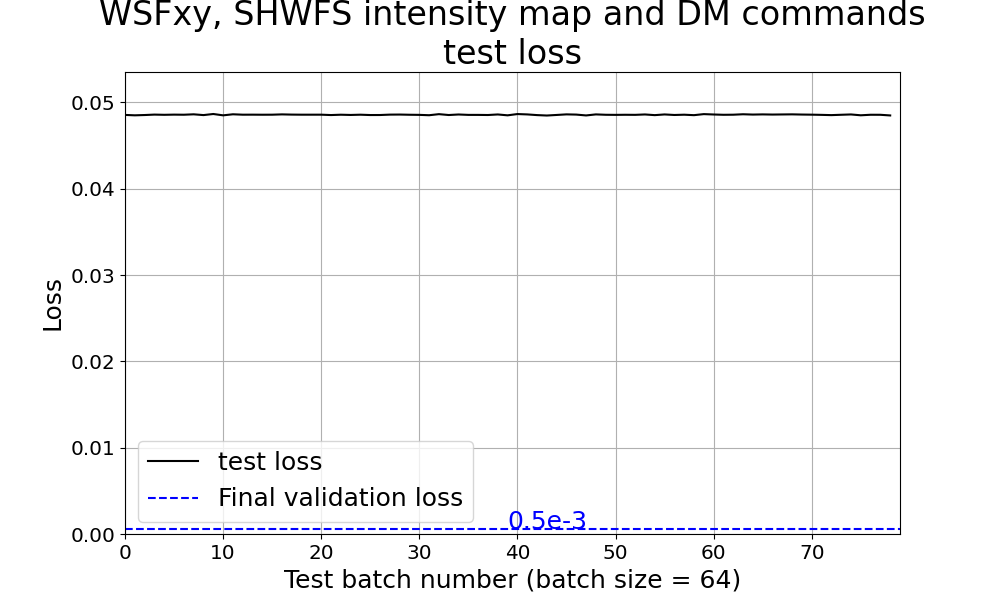

In [66]:
plt.close("all")
plt.figure(figsize=(10, 6))
plt.plot(test_losses, "-k", label= "test loss")
plt.hlines(y=val_loss[-1], xmin=0, xmax=test_losses.shape[0], colors='b', linestyles='--', label="Final validation loss")
plt.text(x=test_losses.shape[0]//2, y=val_loss[-1]*1.1, s=f"{myfunctions.eng_notation(val_loss[-1],1)}", color='b', fontsize=SMALL_SIZE)

plt.title(dataset_name_readable[dataset_number] + "\ntest loss", fontsize=BIGGER_SIZE)
plt.xlabel(f"Test batch number (batch size = {batch_size})", fontsize=SMALL_SIZE)
plt.ylabel("Loss", fontsize=SMALL_SIZE)
plt.xticks(fontsize=SMALL_SIZE*.8)
plt.yticks(fontsize=SMALL_SIZE*.8)
plt.legend(fontsize=SMALL_SIZE)
plt.xlim([0, test_losses.shape[0]])
plt.ylim([0, max(val_loss[-1]*1.1, max(test_losses)*1.1)])
plt.grid()

plt.savefig(outputDir + datasets_name[dataset_number]+ "/test_loss.png")


## Empty the gpu without losing other variables

In [67]:
torch.cuda.empty_cache()